## Idiosyncratic volatility factor: Low-minus-High portfolios (2005-2025)

**Question.** Do stocks with low idiosyncratic volatility earn higher risk-adjusted returns than stocks with high idiosyncratic volatility? This is the low-volatility anomaly. A positive LMH premium is the expected sign under the motivating hypothesis.

**Idiosyncratic volatility.** For each stock and month-end, regress the trailing 60 months of stock excess returns on market excess returns. Idiosyncratic volatility is the standard deviation of the regression residuals, calculated as residual sum of squares divided by $n-2$. Estimates require a full 60-calendar-month window and at least 36 valid paired observations. The raw monthly `total_return` series is used.

**Factor.** Each return month, stocks are ranked into five equal-count quintiles on idiosyncratic volatility estimated through the prior month (no look-ahead). Q1 is lowest volatility and Q5 highest; portfolios are equal-weighted because market capitalization is unavailable. LMH = Q1 - Q5.

**Regression specifications.** Individual-stock time-series and Fama-MacBeth factor-pricing analyses include three separate models: MKT-only, LMH-only, and MKT + LMH. The single-factor models estimate their own betas, separate from joint-model coefficients. Portfolio CAPM regressions and state-difference tests answer distinct, purpose-specific questions.

**Tests.** The portfolio time-series CAPM regressions test whether each portfolio's alpha is zero. Individual-stock time-series tests report alpha and included factor betas for each of the three model specifications. Fama-MacBeth tests report risk prices for each model and each included factor. Standard errors are Newey-West/HAC with six lags; p-values are two-sided normal approximations; confidence intervals are 95%.

Return months run from January 2005 through the end of the data. Limitations include missing delisting returns, possible survivorship bias, and no market capitalization for value-weighting or size/value controls.

**Data checks and winsorization.** The cleaning log records duplicate and missing-return handling and the winsorization step. Each month's cross-section of returns is winsorized at the 1st/99th percentiles (values beyond a cut-off are replaced by the cut-off, not dropped), and the winsorized series is used in the main analysis. The raw series is kept, and the sensitivity section compares raw, 1%/99% and 5%/95% results. The sort characteristic (idiosyncratic volatility) is not clipped: quintiles are formed by rank, so clipping tail values cannot move a stock between quintiles; the sensitivity section verifies this.

In [8]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WINDOW_MONTHS = 60
MIN_OBSERVATIONS = 36
HAC_LAGS = 6
N_QUINTILES = 5
MIN_STOCKS_PER_QUINTILE = 10
SAMPLE_START = pd.Timestamp("2005-01-31")
WINSOR_LOWER, WINSOR_UPPER = 0.01, 0.99

data_dir = Path.cwd()
if not (data_dir / "market_returns_2000_2025.csv").is_file():
    data_dir = data_dir / "CAPM Factors"

# Market and risk-free series.
market = pd.read_csv(data_dir / "market_returns_2000_2025.csv", parse_dates=["date"])
risk_free = pd.read_csv(data_dir / "risk_free_rate_2000_2025.csv", parse_dates=["date"])
monthly = market.merge(risk_free, on="date", how="outer", validate="one_to_one", indicator=True)
unmatched = monthly.loc[monthly["_merge"] != "both", "date"]
if not unmatched.empty:
    raise ValueError(f"Market and risk-free CSV dates do not match: {unmatched.tolist()[:5]}")
if monthly[["market_return", "rf_1m"]].isna().any().any():
    raise ValueError("Market return or risk-free rate contains missing values.")
factors = pd.DataFrame(
    {
        "Mkt-RF": (monthly["market_return"] - monthly["rf_1m"]).to_numpy(),
        "RF": monthly["rf_1m"].to_numpy(),
    },
    index=pd.DatetimeIndex(monthly["date"], name="date"),
).sort_index()
calendar = factors.index
expected_calendar = pd.date_range(calendar.min(), calendar.max(), freq=pd.offsets.MonthEnd())
if not calendar.equals(expected_calendar):
    raise ValueError("Market data must contain one continuous observation per month-end.")

# Stock returns: validate and clean, logging how many observations each step affects.
stocks = pd.read_csv(data_dir / "sp500_stocks_2000_2025_with_permco.csv", parse_dates=["date"])
required_columns = {"date", "permno", "permco", "ticker", "company_name", "total_return"}
missing_columns = required_columns.difference(stocks.columns)
if missing_columns:
    raise ValueError(f"Stock data is missing required columns: {sorted(missing_columns)}")
if stocks["date"].isna().any() or stocks["permco"].isna().any() or stocks["permco"].isna().any():
    raise ValueError("Stock data contains missing dates or company/security identifiers.")
if not stocks["date"].dt.is_month_end.all():
    raise ValueError("Expected month-end observations in the stock return file.")
stocks["total_return"] = pd.to_numeric(stocks["total_return"], errors="raise")
if not stocks["date"].isin(calendar).all():
    raise ValueError("Stock-return dates do not all align with market months.")

cleaning_log = [("Source rows", len(stocks), 0)]


key_columns = ["permco", "date"]

# Find the PERMNO with the most observations for each company
preferred_permno = (
    stocks.groupby(["permco", "permno"])
    .size()
    .rename("observations")
    .reset_index()
    .sort_values(
        ["permco", "observations", "permno"],
        ascending=[True, False, True]
    )
    .drop_duplicates("permco")
    [["permco", "permno"]]
    .rename(columns={"permno": "preferred_permno"})
)

# Match preferred PERMNO to each company
stocks = stocks.merge(preferred_permno, on="permco", how="left")

# Prioritize the preferred share class
stocks["preferred"] = stocks["permno"] == stocks["preferred_permno"]

# Prefer valid returns, then the company's preferred PERMNO
stocks["has_return"] = stocks["total_return"].notna()

stocks = stocks.sort_values(
    ["permco", "date", "has_return", "preferred", "permno"],
    ascending=[True, True, False, False, True]
)

# Count and remove additional share-class observations
n_duplicates = int(stocks.duplicated(key_columns).sum())

stocks = stocks.drop_duplicates(key_columns).copy()

# Remove temporary columns
stocks = stocks.drop(
    columns=["preferred", "preferred_permno", "has_return"]
)

cleaning_log.append((
    "Duplicate share classes removed",
    len(stocks),
    n_duplicates
))

print(f"Additional share-class observations removed: {n_duplicates:,}")

n_missing = int(stocks["total_return"].isna().sum())
stocks = stocks.dropna(subset=["total_return"])
cleaning_log.append(("Missing total_return rows removed", len(stocks), n_missing))

# Winsorize returns at monthly cross-sectional cut-offs: values beyond a cut-off are replaced by
# the cut-off (not dropped). The raw series is kept for the raw-versus-winsorized sensitivity test.
stocks["total_return_raw"] = stocks["total_return"]
lower = stocks.groupby("date")["total_return"].transform(lambda r: r.quantile(WINSOR_LOWER))
upper = stocks.groupby("date")["total_return"].transform(lambda r: r.quantile(WINSOR_UPPER))
n_winsorized = int((~stocks["total_return"].between(lower, upper)).sum())
stocks["total_return"] = stocks["total_return"].clip(lower=lower, upper=upper)
cleaning_log.append(
    (f"Returns winsorized at monthly {WINSOR_LOWER:.0%}/{WINSOR_UPPER:.0%} cut-offs (replaced, not dropped)",
     len(stocks), n_winsorized)
)
cleaning_log = pd.DataFrame(cleaning_log, columns=["step", "rows_remaining", "rows_affected"])

# Wide month x PERMCO panels on the full market calendar: winsorized (main analysis) and raw.
returns_wide = stocks.pivot(index="date", columns="permco", values="total_return").reindex(calendar)
returns_wide_raw = stocks.pivot(index="date", columns="permco", values="total_return_raw").reindex(calendar)
display(cleaning_log)
print(f"Stocks: {returns_wide.shape[1]}; months: {returns_wide.shape[0]} "
      f"({calendar.min():%Y-%m} through {calendar.max():%Y-%m})")


Additional share-class observations removed: 609


,step,rows_remaining,rows_affected
0,Source rows,156560,0
1,Duplicate share classes removed,155951,609
2,Missing total_return rows removed,155946,5
3,Returns winsorized at monthly 1%/99% cut-offs ...,155946,3120


Stocks: 1069; months: 312 (2000-01 through 2025-12)


## Rolling 60-month beta and idiosyncratic volatility

For each stock and month-end, the trailing 60-month CAPM regression of stock excess returns on market excess returns gives the ordinary beta and the residual (idiosyncratic) volatility. Both are computed from rolling sums over paired observations, require a full 60-calendar-month window and at least 36 valid observations, and are NaN if the market variance is zero. The estimate dated t is available after month t closes and is used for the next return month.

The two printed diagnostics are coverage counts, not performance results: the first is the number of PERMNO-month estimates with sufficient usable history; the second identifies when rolling estimates first become available. The estimates are characteristics used to sort portfolios in the following return month.

In [9]:
stock_excess = returns_wide.sub(factors["RF"], axis=0)
market_excess = factors["Mkt-RF"]
valid = stock_excess.notna()

s = stock_excess.where(valid, 0.0)            # stock excess return, zero where missing
m = valid.mul(market_excess, axis=0)          # paired market excess return, zero where missing


def rolling_sum(frame):
    return frame.rolling(WINDOW_MONTHS, min_periods=1).sum()


n_obs = rolling_sum(valid.astype(float))
sum_s, sum_m = rolling_sum(s), rolling_sum(m)
sum_sm, sum_mm, sum_ss = rolling_sum(s * m), rolling_sum(m ** 2), rolling_sum(s ** 2)

with np.errstate(divide="ignore", invalid="ignore"):
    cov_sm = sum_sm - sum_s * sum_m / n_obs
    var_m = sum_mm - sum_m ** 2 / n_obs
    var_s = sum_ss - sum_s ** 2 / n_obs
    beta_all = cov_sm / var_m
    residual_ss = var_s - cov_sm ** 2 / var_m
    idio_vol_all = np.sqrt((residual_ss / (n_obs - 2)).clip(lower=0))

usable = (n_obs >= MIN_OBSERVATIONS) & (var_m > 0)
usable.iloc[: WINDOW_MONTHS - 1] = False       # require a full 60-calendar-month window
beta_est = beta_all.where(usable)
idio_vol_est = idio_vol_all.where(usable)
print(f"Stock-month estimates available: {int(usable.to_numpy().sum()):,}")
print(f"First estimation month: {idio_vol_est.dropna(how='all').index.min():%Y-%m}")


Stock-month estimates available: 120,977
First estimation month: 2004-12


## Low-minus-High idiosyncratic volatility portfolios and CAPM alpha

Quintiles are formed each month on idiosyncratic volatility estimated through the prior month. Q1 holds the lowest-volatility stocks and Q5 the highest. LMH is Q1 minus Q5.

**Figures and tables in this section.** Figure 1 compares each portfolio's CAPM alpha and market beta; bars are estimates and whiskers are 95% HAC confidence intervals, so intervals crossing zero indicate estimates not distinguishable from zero at the 5% level. Figure 2 plots monthly LMH returns against market excess returns; the fitted line's intercept is alpha and its slope is market beta. Figure 3 shows compounded growth of a notional dollar in each portfolio's monthly excess returns; it is a historical path, not a risk-adjusted performance measure. The portfolio summary table reports mean and volatility of monthly excess returns, average number of stocks, and average lagged sorting volatility and market beta. The CAPM table reports alpha and market beta, HAC errors, confidence intervals, p-values, R-squared, and sample months; alpha tests risk-adjusted performance while beta describes market exposure.

**What the current results show (returns winsorized at 1%/99%).** In Figure 1, portfolio market beta rises from Q1 to Q5, while the LMH beta is negative (about -0.64), so the spread tends to move opposite the market; Figure 2's downward fitted line shows the same thing. Q5 has the highest average market sensitivity and higher volatility than Q1. The LMH mean excess return is close to zero, but its CAPM alpha is positive (about 0.50% per month) with a 95% interval that excludes zero. Because LMH loads negatively on the market, its alpha comes from the high-volatility leg (Q5) having a negative alpha, not from low-volatility stocks earning abnormally high returns. This alpha is sensitive to outlier treatment: with raw returns it is 0.32% and not significant (see the sensitivity section). Figure 3 is descriptive; use the CAPM alpha and its interval for risk-adjusted inference.

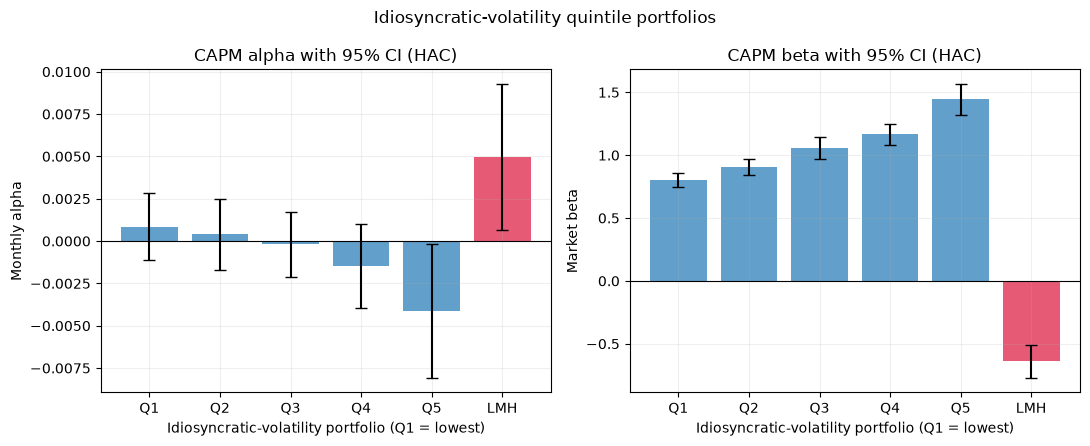

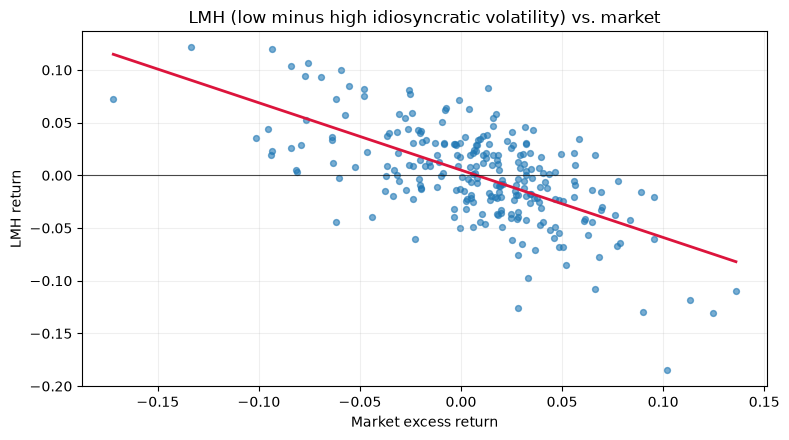

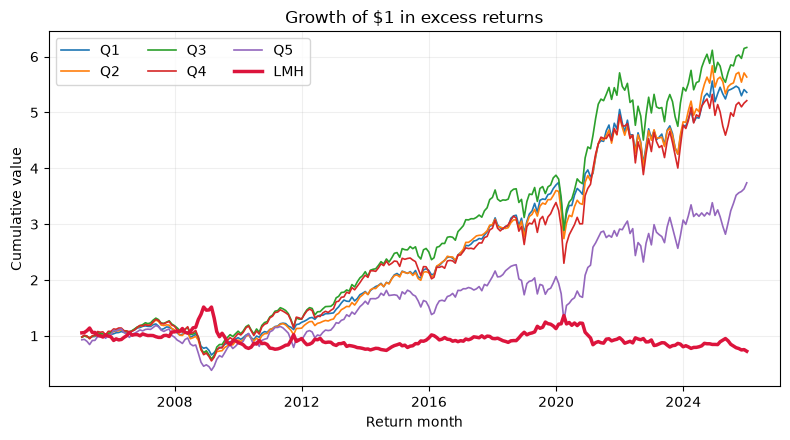

Portfolio months (inclusive): 2005-01 through 2025-12 (252 months)
Quintiles are formed each month on idiosyncratic volatility estimated through the prior month; equal-weighted; LMH = Q1 - Q5.
Inference: Newey-West/HAC standard errors (6 lags); p-values use the normal approximation.


,mean_excess_return,std_dev,mean_stocks_per_month,avg_idio_vol,avg_beta
portfolio,,,,,
Q1,0.007444,0.038714,93.043651,0.042410,0.765759
Q2,0.007819,0.042974,90.869048,0.053100,0.853544
Q3,0.008467,0.049388,88.698413,0.062562,1.018763
Q4,0.008078,0.054651,86.607143,0.075298,1.173301
Q5,0.007712,0.069998,77.813492,0.102254,1.596236
LMH,-0.000268,0.044730,NaN,NaN,NaN


,portfolio,term,estimate,annualized_estimate,hac_std_error,t_stat,p_value_normal_approx,ci_95_low,ci_95_high,r_squared,n_months
0,Q1,alpha,0.000857,0.010284,0.001011,0.847344,3.968034e-01,-0.001125,0.002839,0.842730,252
1,Q1,beta,0.804053,NaN,0.027152,29.613008,1.016212e-192,0.750835,0.857271,0.842730,252
2,Q2,alpha,0.000388,0.004652,0.001061,0.365382,7.148265e-01,-0.001692,0.002467,0.870722,252
3,Q2,beta,0.907227,NaN,0.032657,27.780491,7.464888e-170,0.843219,0.971235,0.870722,252
4,Q3,alpha,-0.000199,-0.002392,0.000983,-0.202856,8.392476e-01,-0.002125,0.001727,0.896566,252
5,Q3,beta,1.058000,NaN,0.043864,24.119940,1.544323e-128,0.972026,1.143974,0.896566,252
6,Q4,alpha,-0.001472,-0.017666,0.001257,-1.171561,2.413734e-01,-0.003935,0.000991,0.889109,252
7,Q4,beta,1.165872,NaN,0.042147,27.662214,1.989924e-168,1.083265,1.248480,0.889109,252
8,Q5,alpha,-0.004109,-0.049313,0.002023,-2.031530,4.220128e-02,-0.008074,-0.000145,0.830306,252
9,Q5,beta,1.443050,NaN,0.062659,23.030374,2.313819e-117,1.320239,1.565860,0.830306,252


LMH alpha: estimate=0.004966, 95% CI=(0.000660, 0.009272), p=0.0238; statistically significant at 5%.
LMH beta: estimate=-0.638996, 95% CI=(-0.770566, -0.507426), p=0.0000; statistically significant at 5%.


In [10]:
# Characteristics lagged one month: estimated through t-1, used for return month t.
lag_vol = idio_vol_est.shift(1)
lag_beta = beta_est.shift(1)

sample_months = calendar[calendar >= SAMPLE_START]
n_ranked = lag_vol.notna().sum(axis=1)
rank = lag_vol.rank(axis=1, method="first")
quintile = ((rank - 1).mul(N_QUINTILES).floordiv(n_ranked, axis=0) + 1)
quintile = quintile.where(n_ranked.ge(N_QUINTILES * MIN_STOCKS_PER_QUINTILE), np.nan)
quintile.loc[~quintile.index.isin(sample_months)] = np.nan

quintile_returns = pd.DataFrame({
    f"Q{q}": stock_excess.where(quintile.eq(q)).mean(axis=1) for q in range(1, N_QUINTILES + 1)
}).dropna(how="any")
quintile_returns["LMH"] = quintile_returns["Q1"] - quintile_returns[f"Q{N_QUINTILES}"]
mkt_excess = market_excess.reindex(quintile_returns.index)


def newey_west_variance(scores, lags=HAC_LAGS):
    """Bartlett-weighted long-run covariance of the columns of `scores` (T x k)."""
    meat = scores.T @ scores
    for lag in range(1, min(lags, len(scores) - 1) + 1):
        gamma = scores[lag:].T @ scores[:-lag]
        meat += (1 - lag / (lags + 1)) * (gamma + gamma.T)
    return meat


def capm_regression(y, x):
    """OLS of y on [1, x] with Newey-West (Bartlett) standard errors."""
    y = np.asarray(y, dtype=float)
    design = np.column_stack([np.ones(len(y)), np.asarray(x, dtype=float)])
    coefficients = np.linalg.solve(design.T @ design, design.T @ y)
    residuals = y - design @ coefficients
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ newey_west_variance(design * residuals[:, None]) @ bread
    r_squared = 1 - residuals @ residuals / np.sum((y - y.mean()) ** 2)
    return coefficients, np.sqrt(np.diag(covariance)), r_squared, len(y)


portfolio_rows, portfolio_fits = [], {}
for portfolio in quintile_returns.columns:
    coefficients, std_errors, r_squared, n_months = capm_regression(quintile_returns[portfolio], mkt_excess)
    portfolio_fits[portfolio] = coefficients
    for term, estimate, std_error in zip(["alpha", "beta"], coefficients, std_errors):
        t_stat = estimate / std_error
        portfolio_rows.append({
            "portfolio": portfolio,
            "term": term,
            "estimate": estimate,
            "annualized_estimate": estimate * 12 if term == "alpha" else np.nan,
            "hac_std_error": std_error,
            "t_stat": t_stat,
            "p_value_normal_approx": math.erfc(abs(t_stat) / math.sqrt(2)),
            "ci_95_low": estimate - 1.96 * std_error,
            "ci_95_high": estimate + 1.96 * std_error,
            "r_squared": r_squared,
            "n_months": n_months,
        })
vol_capm = pd.DataFrame(portfolio_rows)

# Characteristics of the stocks in each quintile (the sort should leave ordinary beta similar).
in_sample = quintile.index.isin(quintile_returns.index)
summary = pd.DataFrame({
    "mean_excess_return": quintile_returns.mean(),
    "std_dev": quintile_returns.std(),
}).rename_axis("portfolio")
stats_by_quintile = {
    "mean_stocks_per_month": lambda q: (quintile.eq(q) & stock_excess.notna()).loc[in_sample].sum(axis=1).mean(),
    "avg_idio_vol": lambda q: np.nanmean(lag_vol.where(quintile.eq(q)).loc[in_sample].to_numpy()),
    "avg_beta": lambda q: np.nanmean(lag_beta.where(quintile.eq(q)).loc[in_sample].to_numpy()),
}
for column, function in stats_by_quintile.items():
    summary[column] = [function(int(p[1])) if p != "LMH" else np.nan for p in summary.index]

# Figure 1: alpha and beta with 95% confidence intervals for every portfolio.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, term in zip(axes, ["alpha", "beta"]):
    rows = vol_capm.loc[vol_capm["term"].eq(term)].set_index("portfolio")
    error = np.vstack([rows["estimate"] - rows["ci_95_low"], rows["ci_95_high"] - rows["estimate"]])
    colors = ["crimson" if p == "LMH" else "tab:blue" for p in rows.index]
    ax.bar(rows.index, rows["estimate"], color=colors, alpha=0.7)
    ax.errorbar(rows.index, rows["estimate"], yerr=error, fmt="none", ecolor="black", capsize=4)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"CAPM {term} with 95% CI (HAC)", xlabel="Idiosyncratic-volatility portfolio (Q1 = lowest)",
           ylabel="Monthly alpha" if term == "alpha" else "Market beta")
    ax.grid(alpha=0.2)
fig.suptitle("Idiosyncratic-volatility quintile portfolios")
fig.tight_layout()
display(fig)
plt.close(fig)

# Figure 2: LMH spread against the market, with the fitted CAPM line.
alpha_hat, beta_hat = portfolio_fits["LMH"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(mkt_excess, quintile_returns["LMH"], alpha=0.6, s=18)
x_line = np.linspace(mkt_excess.min(), mkt_excess.max(), 100)
ax.plot(x_line, alpha_hat + beta_hat * x_line, color="crimson", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
ax.set(title="LMH (low minus high idiosyncratic volatility) vs. market",
       xlabel="Market excess return", ylabel="LMH return")
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

# Figure 3: cumulative growth of each quintile's excess return and the spread.
fig, ax = plt.subplots(figsize=(8, 4.5))
growth = (1 + quintile_returns).cumprod()
for portfolio in growth.columns:
    ax.plot(growth.index, growth[portfolio], label=portfolio,
            linewidth=2.5 if portfolio == "LMH" else 1.2,
            color="crimson" if portfolio == "LMH" else None)
ax.set(title="Growth of $1 in excess returns", xlabel="Return month", ylabel="Cumulative value")
ax.legend(ncol=3)
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

print(f"Portfolio months (inclusive): {quintile_returns.index.min():%Y-%m} through {quintile_returns.index.max():%Y-%m} "
      f"({len(quintile_returns)} months)")
print("Quintiles are formed each month on idiosyncratic volatility estimated through the prior month; equal-weighted; LMH = Q1 - Q5.")
print(f"Inference: Newey-West/HAC standard errors ({HAC_LAGS} lags); p-values use the normal approximation.")
display(summary, vol_capm)

for term in ["alpha", "beta"]:
    result = vol_capm.loc[vol_capm["portfolio"].eq("LMH") & vol_capm["term"].eq(term)].iloc[0]
    significance = (
        "statistically significant at 5%"
        if result["p_value_normal_approx"] < 0.05
        else "not statistically significant at 5%"
    )
    print(
        f"LMH {term}: estimate={result['estimate']:.6f}, "
        f"95% CI=({result['ci_95_low']:.6f}, {result['ci_95_high']:.6f}), "
        f"p={result['p_value_normal_approx']:.4f}; {significance}."
    )


## Individual-stock time-series regressions: MKT, LMH, and joint models

Each stock's monthly excess returns are regressed on three specifications: market excess return only (MKT), low-minus-high idiosyncratic-volatility return only (LMH = Q1 - Q5), and both factors together. The model estimates the intercept and each included beta, with Newey-West/HAC standard errors (six lags), two-sided normal-approximation p-values, and 95% confidence intervals. Each model uses that stock's available months with the required factors and requires at least 36 observations.

The significance summary reports the eligible-stock count and share with significant factor loadings separately by model and factor. LMH is formed from portfolios in the same stock universe, so its loadings are descriptive, not an independent out-of-sample test. Results are not adjusted for multiple testing.

In [11]:
def ols_hac(y, regressors):
    """OLS of y on [1, regressors] with Newey-West standard errors."""
    y = np.asarray(y, dtype=float)
    design = np.column_stack([np.ones(len(y)), np.asarray(regressors, dtype=float)])
    coefficients = np.linalg.solve(design.T @ design, design.T @ y)
    residuals = y - design @ coefficients
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ newey_west_variance(design * residuals[:, None]) @ bread
    r_squared = 1 - residuals @ residuals / np.sum((y - y.mean()) ** 2)
    adj_r_squared = 1 - (1 - r_squared) * (len(y) - 1) / (len(y) - design.shape[1])
    return coefficients, np.sqrt(np.diag(covariance)), r_squared, adj_r_squared


stock_model_specs = {
    "MKT only": ["MKT"],
    "LMH only": ["LMH"],
    "MKT + LMH": ["MKT", "LMH"],
}
model_factors = pd.DataFrame({"MKT": mkt_excess, "LMH": quintile_returns["LMH"]})
stock_regression_rows = []

for permco, stock_returns in stock_excess.loc[model_factors.index].items():
    for model_name, factor_names in stock_model_specs.items():
        sample = pd.concat(
            [stock_returns.rename("stock_excess"), model_factors[factor_names]], axis=1
        ).dropna()
        n_months = len(sample)
        if n_months < MIN_OBSERVATIONS:
            continue

        regressors = sample[factor_names].to_numpy(dtype=float)
        design = np.column_stack([np.ones(n_months), regressors])
        if np.linalg.matrix_rank(design) < design.shape[1]:
            continue

        coefficients, std_errors, r_squared, adj_r_squared = ols_hac(
            sample["stock_excess"], regressors
        )
        for term, estimate, std_error in zip(
            ["alpha", *factor_names], coefficients, std_errors
        ):
            t_stat = estimate / std_error if std_error > 0 else np.nan
            p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
            stock_regression_rows.append({
                "permco": permco,
                "model": model_name,
                "term": term,
                "estimate": estimate,
                "hac_std_error": std_error,
                "t_stat": t_stat,
                "p_value_normal_approx": p_value,
                "ci_95_low": estimate - 1.96 * std_error,
                "ci_95_high": estimate + 1.96 * std_error,
                "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
                "r_squared": r_squared,
                "adjusted_r_squared": adj_r_squared,
                "n_months": n_months,
            })

stock_regressions = pd.DataFrame(stock_regression_rows)
if stock_regressions.empty:
    raise ValueError("No individual-stock regressions met the sample and rank requirements.")

beta_results = stock_regressions.loc[stock_regressions["term"].ne("alpha")]
beta_significance_summary = (
    beta_results.groupby(["model", "term"], as_index=False)
    .agg(
        eligible_stocks=("permco", "nunique"),
        significant_stocks_5pct=("significant_5pct", "sum"),
        mean_beta=("estimate", "mean"),
        median_beta=("estimate", "median"),
    )
)
beta_significance_summary["significant_percent"] = (
    100 * beta_significance_summary["significant_stocks_5pct"]
    / beta_significance_summary["eligible_stocks"]
)
positive = beta_results.loc[
    beta_results["significant_5pct"] & beta_results["estimate"].gt(0)
].groupby(["model", "term"])["permco"].nunique()
negative = beta_results.loc[
    beta_results["significant_5pct"] & beta_results["estimate"].lt(0)
].groupby(["model", "term"])["permco"].nunique()
summary_keys = pd.MultiIndex.from_frame(beta_significance_summary[["model", "term"]])
beta_significance_summary["significant_positive"] = summary_keys.map(positive).fillna(0).astype(int)
beta_significance_summary["significant_negative"] = summary_keys.map(negative).fillna(0).astype(int)

print(
    f"Individual-stock time-series regressions estimate MKT-only, LMH-only, and joint models; "
    f"{model_factors.index.min():%Y-%m} through {model_factors.index.max():%Y-%m}."
)
print(
    f"Inference: Newey-West/HAC standard errors ({HAC_LAGS} lags); "
    "two-sided normal-approximation p-values; 5% significance level."
)
print("Significance of each factor beta by model:")
display(beta_significance_summary)
print("Individual-stock coefficient estimates, including confidence intervals:")
display(stock_regressions)
print(
    "LMH is formed from volatility-sorted portfolios in this same stock universe; "
    "interpret significance as descriptive, especially without multiple-testing adjustment."
)


Individual-stock time-series regressions estimate MKT-only, LMH-only, and joint models; 2005-01 through 2025-12.
Inference: Newey-West/HAC standard errors (6 lags); two-sided normal-approximation p-values; 5% significance level.
Significance of each factor beta by model:


,model,term,eligible_stocks,significant_stocks_5pct,mean_beta,median_beta,significant_percent,significant_positive,significant_negative
0,LMH only,LMH,779,619,-0.789980,-0.718937,79.460847,7,612
1,MKT + LMH,LMH,779,331,-0.173707,-0.104135,42.490372,130,201
2,MKT + LMH,MKT,779,733,0.996869,0.983748,94.094994,733,0
3,MKT only,MKT,779,769,1.115734,1.084889,98.716303,768,1


Individual-stock coefficient estimates, including confidence intervals:


,permco,model,term,estimate,hac_std_error,t_stat,p_value_normal_approx,ci_95_low,ci_95_high,significant_5pct,r_squared,adjusted_r_squared,n_months
0,7,MKT only,alpha,0.015598,0.004557,3.422921,6.195218e-04,0.006666,0.024530,True,0.344230,0.341607,252
1,7,MKT only,MKT,1.156095,0.091760,12.599159,2.134076e-36,0.976246,1.335944,True,0.344230,0.341607,252
2,7,LMH only,alpha,0.024879,0.005015,4.961210,7.005556e-07,0.015050,0.034707,True,0.132195,0.128724,252
3,7,LMH only,LMH,-0.707948,0.141370,-5.007749,5.507033e-07,-0.985034,-0.430862,True,0.132195,0.128724,252
4,7,MKT + LMH,alpha,0.015487,0.004710,3.288320,1.007872e-03,0.006256,0.024719,True,0.344309,0.339043,252
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5448,59446,LMH only,alpha,0.002109,0.010109,0.208629,8.347380e-01,-0.017704,0.021922,False,0.169170,0.144734,36
5449,59446,LMH only,LMH,-0.926766,0.262865,-3.525640,4.224615e-04,-1.441981,-0.411551,True,0.169170,0.144734,36
5450,59446,MKT + LMH,alpha,-0.007281,0.009110,-0.799246,4.241480e-01,-0.025138,0.010575,False,0.270858,0.226667,36
5451,59446,MKT + LMH,MKT,0.920592,0.318717,2.888434,3.871647e-03,0.295907,1.545276,True,0.270858,0.226667,36


LMH is formed from volatility-sorted portfolios in this same stock universe; interpret significance as descriptive, especially without multiple-testing adjustment.


## Fama-MacBeth factor pricing

The notebook estimates three independent two-pass factor-pricing models for stock excess returns:

- **MKT only:** estimate and price market beta alone.
- **LMH only:** estimate and price LMH beta alone.
- **MKT + LMH:** estimate and price both betas jointly.

Each first-pass beta uses trailing monthly data ending before the return month (60 months, at least 36 valid observations). Single-factor betas are estimated independently, not reused from the joint model. The second pass estimates monthly intercept and factor prices; their time-series averages are tested against zero using six-lag Newey-West/HAC standard errors, two-sided normal-approximation p-values, and 95% confidence intervals.

In [12]:
FACTOR_WINDOW_MONTHS = 60
FACTOR_MIN_OBSERVATIONS = 36

# The factor return in month t is only used with stock returns from t onward;
# each stock's beta is estimated using the preceding 60 calendar months.
fmb_factors = pd.DataFrame({
    "MKT": market_excess,
    "LMH": quintile_returns["LMH"],
}).dropna().sort_index()
fmb_calendar = fmb_factors.index
if not fmb_calendar.equals(pd.date_range(
    fmb_calendar.min(), fmb_calendar.max(), freq=pd.offsets.MonthEnd()
)):
    raise ValueError("Fama-MacBeth factor data must have a continuous month-end calendar.")

fmb_first_pass_rows = []
fmb_monthly_rows = []
stock_ids = stock_excess.columns
stock_return_values = stock_excess.reindex(
    index=fmb_calendar, columns=stock_ids
).to_numpy(dtype=float)
fmb_factor_values = fmb_factors[["MKT", "LMH"]].to_numpy(dtype=float)

for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    return_month = fmb_calendar[target_position]
    window_start = target_position - FACTOR_WINDOW_MONTHS
    window_end = target_position
    historical_returns = stock_return_values[window_start:window_end]
    historical_factors = fmb_factor_values[window_start:window_end]
    first_pass_design = np.column_stack([np.ones(FACTOR_WINDOW_MONTHS), historical_factors])
    valid_history = np.isfinite(historical_returns)
    n_valid = valid_history.sum(axis=0)
    safe_returns = np.where(valid_history, historical_returns, 0.0)
    valid_weights = valid_history.astype(float)

    gram_matrices = np.einsum(
        "ti,tj,tn->nij", first_pass_design, first_pass_design, valid_weights, optimize=True
    )
    right_hand_sides = np.einsum(
        "ti,tn->ni", first_pass_design, safe_returns, optimize=True
    )
    eligible = n_valid >= FACTOR_MIN_OBSERVATIONS
    full_rank = np.zeros(len(stock_ids), dtype=bool)
    candidate_indices = np.flatnonzero(eligible)
    if len(candidate_indices):
        full_rank[candidate_indices] = (
            np.linalg.matrix_rank(gram_matrices[candidate_indices]) == first_pass_design.shape[1]
        )

    beta_coefficients = np.full((len(stock_ids), first_pass_design.shape[1]), np.nan)
    valid_indices = np.flatnonzero(full_rank)
    if len(valid_indices):
        beta_coefficients[valid_indices] = np.linalg.solve(
            gram_matrices[valid_indices], right_hand_sides[valid_indices, :, None]
        )[..., 0]

    next_returns = stock_return_values[target_position]
    cross_section_mask = full_rank & np.isfinite(next_returns)
    cross_section_rows = np.column_stack([
        next_returns[cross_section_mask], beta_coefficients[cross_section_mask, 1:]
    ])
    for permco, beta_mkt, beta_lmh in zip(
        stock_ids[cross_section_mask],
        beta_coefficients[cross_section_mask, 1],
        beta_coefficients[cross_section_mask, 2],
    ):
        fmb_first_pass_rows.append({
            "return_month": return_month,
            "permco": permco,
            "beta_mkt": beta_mkt,
            "beta_lmh": beta_lmh,
        })

    if len(cross_section_rows) < 4:
        continue
    y = cross_section_rows[:, 0]
    design = np.column_stack([np.ones(len(y)), cross_section_rows[:, 1:]])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    gamma, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ gamma
    total_ss = np.sum((y - y.mean()) ** 2)
    cross_section_r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
    fmb_monthly_rows.append({
        "return_month": return_month,
        "gamma_0": gamma[0],
        "gamma_mkt": gamma[1],
        "gamma_lmh": gamma[2],
        "n_stocks": len(y),
        "cross_section_r_squared": cross_section_r_squared,
    })

fmb_first_pass_betas = pd.DataFrame(fmb_first_pass_rows)
fmb_monthly_prices = pd.DataFrame(fmb_monthly_rows).set_index("return_month").sort_index()
if fmb_monthly_prices.empty:
    raise ValueError("No monthly Fama-MacBeth cross-sectional regressions were estimable.")

fmb_summary_rows = []
for term, column in [
    ("Intercept", "gamma_0"),
    ("MKT beta", "gamma_mkt"),
    ("LMH beta", "gamma_lmh"),
]:
    monthly_prices = fmb_monthly_prices[column].to_numpy(dtype=float)
    n_months = len(monthly_prices)
    mean_price = monthly_prices.mean()
    demeaned_scores = (monthly_prices - mean_price).reshape(-1, 1)
    hac_variance_of_sum = newey_west_variance(demeaned_scores, lags=HAC_LAGS)[0, 0]
    standard_error = np.sqrt(max(hac_variance_of_sum, 0) / n_months**2)
    t_stat = mean_price / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    fmb_summary_rows.append({
        "term": term,
        "mean_monthly_risk_premium": mean_price,
        "hac_std_error": standard_error,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_95_low": mean_price - 1.96 * standard_error,
        "ci_95_high": mean_price + 1.96 * standard_error,
        "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
        "n_months": n_months,
        "average_stocks_per_month": fmb_monthly_prices["n_stocks"].mean(),
    })

fmb_summary = pd.DataFrame(fmb_summary_rows)
lmh_test = fmb_summary.loc[fmb_summary["term"].eq("LMH beta")].iloc[0]
print(
    f"Fama-MacBeth sample: {fmb_monthly_prices.index.min():%Y-%m} through "
    f"{fmb_monthly_prices.index.max():%Y-%m}; {len(fmb_monthly_prices)} monthly cross-sections; "
    f"average {fmb_monthly_prices['n_stocks'].mean():.1f} stocks per month."
)
print(f"First-pass stock betas use the prior {FACTOR_WINDOW_MONTHS} months (minimum {FACTOR_MIN_OBSERVATIONS} observations).")
print(f"Second-pass null for LMH: H0: mean gamma_LMH = 0; Newey-West/HAC lags = {HAC_LAGS}.")
display(fmb_summary)
print(
    f"LMH risk premium: {lmh_test['mean_monthly_risk_premium']:.6f} per month; "
    f"t={lmh_test['t_stat']:.3f}, p={lmh_test['p_value']:.4f}; "
    f"{'reject' if lmh_test['significant_5pct'] else 'fail to reject'} H0 at 5%."
)
if lmh_test["significant_5pct"]:
    direction = "positive" if lmh_test["mean_monthly_risk_premium"] > 0 else "negative"
    fmb_conclusion = (
        f"Conclusion: Reject H0 at the 5% level. The estimated LMH risk premium is "
        f"statistically significant and {direction} ({lmh_test['mean_monthly_risk_premium']:.6f} "
        "per month). This is evidence that LMH exposure is priced in this sample."
    )
else:
    fmb_conclusion = (
        f"Conclusion: Fail to reject H0 at the 5% level (p={lmh_test['p_value']:.4f}). "
        f"The estimated LMH risk premium is {lmh_test['mean_monthly_risk_premium']:.6f} per month, "
        "but the data do not provide statistically significant evidence that LMH exposure is priced. "
        "This does not prove the true premium is exactly zero."
    )
print(fmb_conclusion)

# One-factor Fama-MacBeth: estimate each stock's LMH beta without MKT in pass one.
fmb_lmh_only_monthly_rows = []
for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    return_month = fmb_calendar[target_position]
    window_start = target_position - FACTOR_WINDOW_MONTHS
    history = stock_return_values[window_start:target_position]
    lmh_history = fmb_factor_values[window_start:target_position, 1]
    valid = np.isfinite(history)
    counts = valid.sum(axis=0)
    safe_history = np.where(valid, history, 0.0)
    sum_stock = safe_history.sum(axis=0)
    sum_lmh = valid.T @ lmh_history
    sum_stock_lmh = safe_history.T @ lmh_history
    sum_lmh_squared = valid.T @ (lmh_history**2)
    centered_covariance = sum_stock_lmh - sum_stock * sum_lmh / np.maximum(counts, 1)
    centered_variance = sum_lmh_squared - sum_lmh**2 / np.maximum(counts, 1)
    eligible = (counts >= FACTOR_MIN_OBSERVATIONS) & (centered_variance > np.finfo(float).eps)
    beta_lmh = np.full(len(stock_ids), np.nan)
    beta_lmh[eligible] = centered_covariance[eligible] / centered_variance[eligible]

    current_returns = stock_return_values[target_position]
    cross_section_mask = eligible & np.isfinite(current_returns)
    if cross_section_mask.sum() < 3:
        continue
    y = current_returns[cross_section_mask]
    design = np.column_stack([np.ones(len(y)), beta_lmh[cross_section_mask]])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    coefficients, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ coefficients
    total_ss = np.sum((y - y.mean()) ** 2)
    r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
    fmb_lmh_only_monthly_rows.append({
        "return_month": return_month,
        "gamma_0": coefficients[0],
        "gamma_lmh": coefficients[1],
        "n_stocks": len(y),
        "cross_section_r_squared": r_squared,
    })

fmb_lmh_only_monthly_prices = pd.DataFrame(fmb_lmh_only_monthly_rows).set_index("return_month").sort_index()
if fmb_lmh_only_monthly_prices.empty:
    raise ValueError("No LMH-only Fama-MacBeth cross-sectional regressions were estimable.")
lmh_only_summary_rows = []
for term, column in [("Intercept (alpha)", "gamma_0"), ("LMH beta price", "gamma_lmh")]:
    prices = fmb_lmh_only_monthly_prices[column].to_numpy(dtype=float)
    mean_price = prices.mean()
    scores = (prices - mean_price).reshape(-1, 1)
    hac_variance = newey_west_variance(scores, lags=HAC_LAGS)[0, 0]
    standard_error = np.sqrt(max(hac_variance, 0) / len(prices) ** 2)
    t_stat = mean_price / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    lmh_only_summary_rows.append({
        "model": "LMH only",
        "term": term,
        "mean_monthly_risk_price": mean_price,
        "hac_std_error": standard_error,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_95_low": mean_price - 1.96 * standard_error,
        "ci_95_high": mean_price + 1.96 * standard_error,
        "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
        "n_months": len(prices),
        "average_stocks_per_month": fmb_lmh_only_monthly_prices["n_stocks"].mean(),
    })
fmb_lmh_only_summary = pd.DataFrame(lmh_only_summary_rows)
lmh_only_test = fmb_lmh_only_summary.loc[
    fmb_lmh_only_summary["term"].eq("LMH beta price")
].iloc[0]
lmh_only_alpha_test = fmb_lmh_only_summary.loc[
    fmb_lmh_only_summary["term"].eq("Intercept (alpha)")
].iloc[0]
lmh_only_mean = lmh_only_test["mean_monthly_risk_price"]
lmh_only_se = lmh_only_test["hac_std_error"]
lmh_only_t = lmh_only_test["t_stat"]
lmh_only_p = lmh_only_test["p_value"]
print("LMH-only Fama-MacBeth estimates: intercept (alpha) and LMH price of exposure:")
display(fmb_lmh_only_summary)
print(
    f"LMH-only alpha={lmh_only_alpha_test['mean_monthly_risk_price']:.6f} per month "
    f"(p={lmh_only_alpha_test['p_value']:.4f}); LMH premium={lmh_only_mean:.6f} per month "
    f"(p={lmh_only_p:.4f})."
)

# With two factors, each VIF equals 1 / (1 - correlation squared).
factor_correlation = fmb_factors[["MKT", "LMH"]].corr().loc["MKT", "LMH"]
factor_vif = np.inf if np.isclose(abs(factor_correlation), 1.0) else 1 / (1 - factor_correlation**2)
multicollinearity_summary = pd.DataFrame({
    "diagnostic": ["MKT-LMH correlation", "VIF: MKT", "VIF: LMH"],
    "value": [factor_correlation, factor_vif, factor_vif],
})
print("Multicollinearity check for the MKT and LMH factor returns:")
display(multicollinearity_summary)

Fama-MacBeth sample: 2010-01 through 2025-12; 192 monthly cross-sections; average 440.0 stocks per month.
First-pass stock betas use the prior 60 months (minimum 36 observations).
Second-pass null for LMH: H0: mean gamma_LMH = 0; Newey-West/HAC lags = 6.


,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,Intercept,0.007154,0.002292,3.121405,0.001800,0.002662,0.011647,True,192,439.973958
1,MKT beta,0.002679,0.002616,1.024164,0.305758,-0.002448,0.007806,False,192,439.973958
2,LMH beta,-0.000760,0.002378,-0.319684,0.749208,-0.005421,0.003901,False,192,439.973958


LMH risk premium: -0.000760 per month; t=-0.320, p=0.7492; fail to reject H0 at 5%.
Conclusion: Fail to reject H0 at the 5% level (p=0.7492). The estimated LMH risk premium is -0.000760 per month, but the data do not provide statistically significant evidence that LMH exposure is priced. This does not prove the true premium is exactly zero.
LMH-only Fama-MacBeth estimates: intercept (alpha) and LMH price of exposure:


,model,term,mean_monthly_risk_price,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,LMH only,Intercept (alpha),0.008913,0.001757,5.073402,3.907656e-07,0.005470,0.012357,True,192,439.973958
1,LMH only,LMH beta price,-0.001124,0.002341,-0.480169,6.311070e-01,-0.005713,0.003465,False,192,439.973958


LMH-only alpha=0.008913 per month (p=0.0000); LMH premium=-0.001124 per month (p=0.6311).
Multicollinearity check for the MKT and LMH factor returns:


,diagnostic,value
0,MKT-LMH correlation,-0.631427
1,VIF: MKT,1.663064
2,VIF: LMH,1.663064


In [13]:
# Independent MKT-only Fama-MacBeth model (one factor in both passes).
mkt_only_fmb_rows = []
mkt_factor_values = fmb_factors["MKT"].to_numpy(dtype=float)
for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    historical_returns = stock_return_values[
        target_position - FACTOR_WINDOW_MONTHS:target_position
    ]
    historical_market = mkt_factor_values[
        target_position - FACTOR_WINDOW_MONTHS:target_position
    ]
    design_first = np.column_stack([np.ones(FACTOR_WINDOW_MONTHS), historical_market])
    valid_history = np.isfinite(historical_returns)
    valid_weights = valid_history.astype(float)
    safe_returns = np.where(valid_history, historical_returns, 0.0)
    gram = np.einsum(
        "ti,tj,tn->nij", design_first, design_first, valid_weights, optimize=True
    )
    rhs = np.einsum("ti,tn->ni", design_first, safe_returns, optimize=True)
    eligible = valid_history.sum(axis=0) >= FACTOR_MIN_OBSERVATIONS
    full_rank = np.zeros(len(stock_ids), dtype=bool)
    candidates = np.flatnonzero(eligible)
    if len(candidates):
        full_rank[candidates] = np.linalg.matrix_rank(gram[candidates]) == design_first.shape[1]
    betas = np.full((len(stock_ids), 2), np.nan)
    valid_indices = np.flatnonzero(full_rank)
    if len(valid_indices):
        betas[valid_indices] = np.linalg.solve(
            gram[valid_indices], rhs[valid_indices, :, None]
        )[..., 0]

    current_returns = stock_return_values[target_position]
    cross_section = full_rank & np.isfinite(current_returns)
    if cross_section.sum() < 3:
        continue
    y = current_returns[cross_section]
    design_second = np.column_stack([np.ones(len(y)), betas[cross_section, 1]])
    if np.linalg.matrix_rank(design_second) < design_second.shape[1]:
        continue
    gamma, _, _, _ = np.linalg.lstsq(design_second, y, rcond=None)
    residuals = y - design_second @ gamma
    total_ss = np.sum((y - y.mean()) ** 2)
    mkt_only_fmb_rows.append({
        "return_month": fmb_calendar[target_position],
        "gamma_0": gamma[0],
        "gamma_mkt": gamma[1],
        "n_stocks": len(y),
        "cross_section_r_squared": 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan,
    })

mkt_only_fmb_monthly = pd.DataFrame(mkt_only_fmb_rows).set_index("return_month").sort_index()
if mkt_only_fmb_monthly.empty:
    raise ValueError("No MKT-only Fama-MacBeth cross-sections were estimable.")
mkt_only_summary_rows = []
for term, column in [("Intercept", "gamma_0"), ("MKT beta", "gamma_mkt")]:
    prices = mkt_only_fmb_monthly[column].to_numpy(dtype=float)
    mean_price = prices.mean()
    hac_variance = newey_west_variance(
        (prices - mean_price).reshape(-1, 1), lags=HAC_LAGS
    )[0, 0]
    standard_error = np.sqrt(max(hac_variance, 0) / len(prices) ** 2)
    t_stat = mean_price / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    mkt_only_summary_rows.append({
        "model": "MKT only",
        "term": term,
        "mean_monthly_risk_premium": mean_price,
        "hac_std_error": standard_error,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_95_low": mean_price - 1.96 * standard_error,
        "ci_95_high": mean_price + 1.96 * standard_error,
        "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
        "n_months": len(prices),
        "average_stocks_per_month": mkt_only_fmb_monthly["n_stocks"].mean(),
    })
mkt_only_fmb_summary = pd.DataFrame(mkt_only_summary_rows)
print("Independent MKT-only Fama-MacBeth model (MKT beta only in both passes):")
display(mkt_only_fmb_summary)


Independent MKT-only Fama-MacBeth model (MKT beta only in both passes):


,model,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,MKT only,Intercept,0.007711,0.002001,3.852865,0.000117,0.003788,0.011634,True,192,439.973958
1,MKT only,MKT beta,0.002117,0.002714,0.780209,0.435268,-0.003202,0.007437,False,192,439.973958


## Fama-MacBeth sensitivity tests: full sample and crisis months

Both the full-sample test (on the winsorized return panel) and the crisis-only test report the same three independent models: **MKT only**, **LMH only**, and **MKT + LMH**. In each model, first-pass betas use only trailing data; second-pass risk prices test whether the included exposure is priced. Crisis months cover the NBER Great Recession and COVID market shock. Since fewer months qualify, crisis estimates are less precise and should be interpreted cautiously.

In [14]:
# Test 1 (full sample) and Test 2 (crisis months): MKT-only, LMH-only, and joint models.
SENSITIVITY_MODELS = {
    "MKT only": ["MKT"],
    "LMH only": ["LMH"],
    "MKT + LMH": ["MKT", "LMH"],
}


def summarize_fmb_prices(sample_name, model_name, monthly, factor_names):
    rows = []
    terms = [("Intercept", "gamma_0")] + [
        (f"{factor} beta", f"gamma_{factor.lower()}") for factor in factor_names
    ]
    for term, column in terms:
        values = monthly[column].dropna().to_numpy(dtype=float)
        n_months = len(values)
        estimate = values.mean()
        hac = newey_west_variance(
            (values - estimate).reshape(-1, 1),
            lags=min(HAC_LAGS, n_months - 1),
        )[0, 0]
        standard_error = np.sqrt(max(hac, 0) / n_months**2)
        t_stat = estimate / standard_error if standard_error > 0 else np.nan
        p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
        rows.append({
            "sample": sample_name,
            "model": model_name,
            "term": term,
            "mean_monthly_risk_premium": estimate,
            "hac_std_error": standard_error,
            "t_stat": t_stat,
            "p_value": p_value,
            "ci_95_low": estimate - 1.96 * standard_error,
            "ci_95_high": estimate + 1.96 * standard_error,
            "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
            "n_months": n_months,
            "average_stocks_per_month": monthly["n_stocks"].mean(),
        })
    return pd.DataFrame(rows)


# Test 1: the full-sample first-pass/second-pass estimates from the three models.
full_sample_monthly = {
    "MKT only": mkt_only_fmb_monthly,
    "LMH only": fmb_lmh_only_monthly_prices,
    "MKT + LMH": fmb_monthly_prices,
}
test1_fmb_summary = pd.concat([
    summarize_fmb_prices(
        "Test 1 — Full sample, winsorized returns", name, monthly,
        SENSITIVITY_MODELS[name],
    )
    for name, monthly in full_sample_monthly.items()
], ignore_index=True)

# Test 2: use up to 60 prior months, requiring at least 36 valid paired months.
# Define periods of significant market distress
CRISIS_WINDOWS = [
    (pd.Timestamp("2008-01-31"), pd.Timestamp("2009-06-30")),  # Financial crisis
    (pd.Timestamp("2020-02-29"), pd.Timestamp("2020-04-30")),  # COVID-19 crash
]

# Minimum historical observations required
CRISIS_MIN_OBSERVATIONS = 36

# Identify crisis months
crisis_mask = np.zeros(len(fmb_calendar), dtype=bool)

for crisis_start, crisis_end in CRISIS_WINDOWS:
    crisis_mask |= (fmb_calendar >= crisis_start) & (fmb_calendar <= crisis_end)
crisis_rows = {name: [] for name in SENSITIVITY_MODELS}
for position in np.flatnonzero(crisis_mask):
    if position < CRISIS_MIN_OBSERVATIONS:
        continue
    window_start = max(0, position - FACTOR_WINDOW_MONTHS)
    history_returns = stock_return_values[window_start:position]
    current_returns = stock_return_values[position]
    valid = np.isfinite(history_returns)
    counts = valid.sum(axis=0)
    weights = valid.astype(float)
    safe_returns = np.where(valid, history_returns, 0.0)

    for model_name, factor_names in SENSITIVITY_MODELS.items():
        factor_history = fmb_factors[factor_names].to_numpy(dtype=float)[window_start:position]
        first_pass = np.column_stack([np.ones(len(factor_history)), factor_history])
        gram = np.einsum("ti,tj,tn->nij", first_pass, first_pass, weights, optimize=True)
        rhs = np.einsum("ti,tn->ni", first_pass, safe_returns, optimize=True)
        eligible = counts >= CRISIS_MIN_OBSERVATIONS
        full_rank = np.zeros(len(stock_ids), dtype=bool)
        candidates = np.flatnonzero(eligible)
        if len(candidates):
            full_rank[candidates] = np.linalg.matrix_rank(gram[candidates]) == first_pass.shape[1]
        betas = np.full((len(stock_ids), first_pass.shape[1]), np.nan)
        valid_ids = np.flatnonzero(full_rank)
        if len(valid_ids):
            betas[valid_ids] = np.linalg.solve(
                gram[valid_ids], rhs[valid_ids, :, None]
            )[..., 0]

        included = full_rank & np.isfinite(current_returns)
        if included.sum() < len(factor_names) + 2:
            continue
        y = current_returns[included]
        second_pass = np.column_stack([np.ones(len(y)), betas[included, 1:]])
        if np.linalg.matrix_rank(second_pass) < second_pass.shape[1]:
            continue
        gamma, _, _, _ = np.linalg.lstsq(second_pass, y, rcond=None)
        row = {
            "return_month": fmb_calendar[position],
            "gamma_0": gamma[0],
            "n_stocks": len(y),
        }
        for factor_index, factor_name in enumerate(factor_names, start=1):
            row[f"gamma_{factor_name.lower()}"] = gamma[factor_index]
        crisis_rows[model_name].append(row)

crisis_monthly = {
    name: pd.DataFrame(rows).set_index("return_month").sort_index()
    for name, rows in crisis_rows.items()
}
for name, monthly in crisis_monthly.items():
    if monthly.empty:
        raise ValueError(f"Test 2 could not estimate the {name} crisis model.")
test2_fmb_summary = pd.concat([
    summarize_fmb_prices("Test 2 — Crisis months", name, monthly, SENSITIVITY_MODELS[name])
    for name, monthly in crisis_monthly.items()
], ignore_index=True)

print("TEST 1 — Full sample: MKT only, LMH only, and MKT + LMH")
display(test1_fmb_summary)
print("TEST 2 — Crisis months: MKT only, LMH only, and MKT + LMH")
print(
    f"Eligible crisis months: {crisis_monthly['MKT only'].index.min():%Y-%m} through "
    f"{crisis_monthly['MKT only'].index.max():%Y-%m}; "
    f"{len(crisis_monthly['MKT only'])} monthly cross-sections."
)
display(test2_fmb_summary)


TEST 1 — Full sample: MKT only, LMH only, and MKT + LMH


,sample,model,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,"Test 1 — Full sample, winsorized returns",MKT only,Intercept,0.007711,0.002001,3.852865,1.167436e-04,0.003788,0.011634,True,192,439.973958
1,"Test 1 — Full sample, winsorized returns",MKT only,MKT beta,0.002117,0.002714,0.780209,4.352677e-01,-0.003202,0.007437,False,192,439.973958
2,"Test 1 — Full sample, winsorized returns",LMH only,Intercept,0.008913,0.001757,5.073402,3.907656e-07,0.005470,0.012357,True,192,439.973958
3,"Test 1 — Full sample, winsorized returns",LMH only,LMH beta,-0.001124,0.002341,-0.480169,6.311070e-01,-0.005713,0.003465,False,192,439.973958
4,"Test 1 — Full sample, winsorized returns",MKT + LMH,Intercept,0.007154,0.002292,3.121405,1.799904e-03,0.002662,0.011647,True,192,439.973958
5,"Test 1 — Full sample, winsorized returns",MKT + LMH,MKT beta,0.002679,0.002616,1.024164,3.057576e-01,-0.002448,0.007806,False,192,439.973958
6,"Test 1 — Full sample, winsorized returns",MKT + LMH,LMH beta,-0.000760,0.002378,-0.319684,7.492075e-01,-0.005421,0.003901,False,192,439.973958


TEST 2 — Crisis months: MKT only, LMH only, and MKT + LMH
Eligible crisis months: 2008-01 through 2020-04; 21 monthly cross-sections.


,sample,model,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,Test 2 — Crisis months,MKT only,Intercept,-0.027593,0.006696,-4.120988,3.772515e-05,-0.040717,-0.014469,True,21,411.238095
1,Test 2 — Crisis months,MKT only,MKT beta,0.004532,0.015064,0.300878,7.635072e-01,-0.024992,0.034057,False,21,411.238095
2,Test 2 — Crisis months,LMH only,Intercept,-0.024153,0.010541,-2.291386,2.194108e-02,-0.044812,-0.003493,True,21,411.238095
3,Test 2 — Crisis months,LMH only,LMH beta,0.000848,0.012964,0.065429,9.478321e-01,-0.024562,0.026259,False,21,411.238095
4,Test 2 — Crisis months,MKT + LMH,Intercept,-0.032221,0.006381,-5.049368,4.432733e-07,-0.044728,-0.019714,True,21,411.238095
5,Test 2 — Crisis months,MKT + LMH,MKT beta,0.009775,0.015301,0.638846,5.229230e-01,-0.020214,0.039764,False,21,411.238095
6,Test 2 — Crisis months,MKT + LMH,LMH beta,0.003559,0.011206,0.317586,7.507991e-01,-0.018405,0.025523,False,21,411.238095


## Sensitivity: raw returns versus alternative winsorization cut-offs

The main analysis uses returns winsorized at the monthly 1st/99th percentiles. This section re-runs the whole LMH pipeline (rolling beta and idiosyncratic volatility, quintiles, LMH, CAPM alpha, joint MKT + LMH Fama-MacBeth) on three versions of the return panel: raw (no winsorization), 1%/99% (main), and 5%/95%. The 1%/99% row must reproduce the main results above exactly (checked by assertion). The table reports the LMH mean excess return, the LMH CAPM alpha and beta, and the joint Fama-MacBeth LMH premium.

**Sort characteristic.** Quintiles are formed by rank, so clipping the extreme tails of lagged idiosyncratic volatility should not change which quintile a stock falls in. The check below counts how many stock-month quintile assignments would change if the volatility were also winsorized at 1%/99%.

In [15]:
def winsorize_panel(raw_panel, lower_q, upper_q):
    """Clip each month's cross-section at its lower_q/upper_q quantiles (None = leave raw)."""
    if lower_q is None:
        return raw_panel
    return raw_panel.clip(
        lower=raw_panel.quantile(lower_q, axis=1),
        upper=raw_panel.quantile(upper_q, axis=1),
        axis=0,
    )


def idio_vol_quintiles(excess):
    """Rolling 60-month idiosyncratic volatility -> lagged quintiles -> quintile and LMH returns."""
    valid = excess.notna()
    s = excess.where(valid, 0.0)
    m = valid.mul(market_excess, axis=0)
    roll = lambda frame: frame.rolling(WINDOW_MONTHS, min_periods=1).sum()
    n = roll(valid.astype(float))
    sum_s, sum_m = roll(s), roll(m)
    sum_sm, sum_mm, sum_ss = roll(s * m), roll(m ** 2), roll(s ** 2)
    with np.errstate(divide="ignore", invalid="ignore"):
        cov_sm = sum_sm - sum_s * sum_m / n
        var_m = sum_mm - sum_m ** 2 / n
        var_s = sum_ss - sum_s ** 2 / n
        vol = np.sqrt(((var_s - cov_sm ** 2 / var_m) / (n - 2)).clip(lower=0))
    usable = (n >= MIN_OBSERVATIONS) & (var_m > 0)
    usable.iloc[: WINDOW_MONTHS - 1] = False
    lagged_vol = vol.where(usable).shift(1)
    n_rk = lagged_vol.notna().sum(axis=1)
    rk = lagged_vol.rank(axis=1, method="first")
    qnt = ((rk - 1).mul(N_QUINTILES).floordiv(n_rk, axis=0) + 1)
    qnt = qnt.where(n_rk.ge(N_QUINTILES * MIN_STOCKS_PER_QUINTILE), np.nan)
    qnt.loc[~qnt.index.isin(sample_months)] = np.nan
    q_ret = pd.DataFrame({
        f"Q{q}": excess.where(qnt.eq(q)).mean(axis=1) for q in range(1, N_QUINTILES + 1)
    }).dropna(how="any")
    q_ret["LMH"] = q_ret["Q1"] - q_ret[f"Q{N_QUINTILES}"]
    return lagged_vol, qnt, q_ret


def joint_fmb_lmh_price(excess, lmh):
    """Joint MKT + LMH Fama-MacBeth; returns the monthly gamma_LMH series (same steps as above)."""
    factors_fm = pd.DataFrame({"MKT": market_excess, "LMH": lmh}).dropna().sort_index()
    cal = factors_fm.index
    returns_arr = excess.reindex(index=cal, columns=excess.columns).to_numpy(dtype=float)
    factor_arr = factors_fm[["MKT", "LMH"]].to_numpy(dtype=float)
    prices = {}
    for pos in range(FACTOR_WINDOW_MONTHS, len(cal)):
        hist_r = returns_arr[pos - FACTOR_WINDOW_MONTHS:pos]
        design_1 = np.column_stack([np.ones(FACTOR_WINDOW_MONTHS), factor_arr[pos - FACTOR_WINDOW_MONTHS:pos]])
        ok = np.isfinite(hist_r)
        gram = np.einsum("ti,tj,tn->nij", design_1, design_1, ok.astype(float), optimize=True)
        rhs = np.einsum("ti,tn->ni", design_1, np.where(ok, hist_r, 0.0), optimize=True)
        eligible = ok.sum(axis=0) >= FACTOR_MIN_OBSERVATIONS
        full_rank = np.zeros(returns_arr.shape[1], dtype=bool)
        idx = np.flatnonzero(eligible)
        if len(idx):
            full_rank[idx] = np.linalg.matrix_rank(gram[idx]) == design_1.shape[1]
        betas = np.full((returns_arr.shape[1], design_1.shape[1]), np.nan)
        idx = np.flatnonzero(full_rank)
        if len(idx):
            betas[idx] = np.linalg.solve(gram[idx], rhs[idx, :, None])[..., 0]
        nxt = returns_arr[pos]
        mask = full_rank & np.isfinite(nxt)
        if mask.sum() < 4:
            continue
        design_2 = np.column_stack([np.ones(mask.sum()), betas[mask, 1:]])
        if np.linalg.matrix_rank(design_2) < design_2.shape[1]:
            continue
        gamma = np.linalg.lstsq(design_2, nxt[mask], rcond=None)[0]
        prices[cal[pos]] = gamma[2]
    return pd.Series(prices).sort_index()


def mean_with_hac(values):
    values = np.asarray(values, dtype=float)
    mean = values.mean()
    se = np.sqrt(max(newey_west_variance((values - mean).reshape(-1, 1), lags=HAC_LAGS)[0, 0], 0) / len(values) ** 2)
    t_stat = mean / se if se > 0 else np.nan
    return mean, se, t_stat, math.erfc(abs(t_stat) / math.sqrt(2))


winsor_variants = {
    "Raw returns (no winsorization)": (None, None),
    "Winsorized 1% / 99% (main)": (0.01, 0.99),
    "Winsorized 5% / 95%": (0.05, 0.95),
}
winsor_rows = []
for label, (lo_q, hi_q) in winsor_variants.items():
    excess_v = winsorize_panel(returns_wide_raw, lo_q, hi_q).sub(factors["RF"], axis=0)
    _, _, q_ret_v = idio_vol_quintiles(excess_v)
    mkt_v = market_excess.reindex(q_ret_v.index)
    coef, se, _, _ = capm_regression(q_ret_v["LMH"], mkt_v)
    alpha_t = coef[0] / se[0]
    fm_mean, fm_se, fm_t, fm_p = mean_with_hac(joint_fmb_lmh_price(excess_v, q_ret_v["LMH"]))
    winsor_rows.append({
        "specification": label,
        "LMH mean excess return": q_ret_v["LMH"].mean(),
        "LMH CAPM alpha": coef[0],
        "alpha t-stat": alpha_t,
        "alpha p-value": math.erfc(abs(alpha_t) / math.sqrt(2)),
        "LMH CAPM beta": coef[1],
        "joint FM LMH premium": fm_mean,
        "FM t-stat": fm_t,
        "FM p-value": fm_p,
        "portfolio months": len(q_ret_v),
    })
winsor_sensitivity = pd.DataFrame(winsor_rows).set_index("specification")

# The 1%/99% row must reproduce the main results exactly.
main_alpha = vol_capm.loc[vol_capm["portfolio"].eq("LMH") & vol_capm["term"].eq("alpha"), "estimate"].iloc[0]
main_fm = fmb_summary.loc[fmb_summary["term"].eq("LMH beta"), "mean_monthly_risk_premium"].iloc[0]
main_row = winsor_sensitivity.loc["Winsorized 1% / 99% (main)"]
assert np.isclose(main_row["LMH CAPM alpha"], main_alpha, rtol=0, atol=1e-12)
assert np.isclose(main_row["joint FM LMH premium"], main_fm, rtol=0, atol=1e-12)

print("Sensitivity of the LMH results to winsorization of returns (monthly units; HAC, 6 lags):")
display(winsor_sensitivity)

# Sort characteristic: would winsorizing lagged idiosyncratic volatility change any quintile?
vol_sample = lag_vol.loc[sample_months]
vol_lo = vol_sample.quantile(WINSOR_LOWER, axis=1)
vol_hi = vol_sample.quantile(WINSOR_UPPER, axis=1)
n_vol_outside = int((vol_sample.lt(vol_lo, axis=0) | vol_sample.gt(vol_hi, axis=0)).sum().sum())
vol_clipped = lag_vol.clip(lower=vol_lo.reindex(lag_vol.index), upper=vol_hi.reindex(lag_vol.index), axis=0)
n_rk = vol_clipped.notna().sum(axis=1)
q_clipped = ((vol_clipped.rank(axis=1, method="first") - 1).mul(N_QUINTILES).floordiv(n_rk, axis=0) + 1)
q_clipped = q_clipped.where(n_rk.ge(N_QUINTILES * MIN_STOCKS_PER_QUINTILE), np.nan)
q_clipped.loc[~q_clipped.index.isin(sample_months)] = np.nan
changed = int(((q_clipped != quintile) & (q_clipped.notna() | quintile.notna())).sum().sum())
assigned = int(quintile.loc[sample_months].notna().sum().sum())
print(f"Lagged idiosyncratic-volatility values outside the monthly {WINSOR_LOWER:.0%}/{WINSOR_UPPER:.0%} cut-offs: "
      f"{n_vol_outside:,} of {assigned:,} sorted stock-months.")
print(f"Quintile assignments that would change if volatility were also winsorized: {changed:,} "
      f"({changed / assigned:.2%} of sorted stock-months; changes arise only from tie-breaking among clipped values).")


Sensitivity of the LMH results to winsorization of returns (monthly units; HAC, 6 lags):


,LMH mean excess return,LMH CAPM alpha,alpha t-stat,alpha p-value,LMH CAPM beta,joint FM LMH premium,FM t-stat,FM p-value,portfolio months
specification,,,,,,,,,
Raw returns (no winsorization),-0.001864,0.003244,1.378321,0.168104,-0.623595,-0.001001,-0.439513,0.660290,252
Winsorized 1% / 99% (main),-0.000268,0.004966,2.260600,0.023784,-0.638996,-0.000760,-0.319684,0.749208,252
Winsorized 5% / 95%,0.000326,0.005069,2.648406,0.008087,-0.579021,-0.000484,-0.223388,0.823234,252


Lagged idiosyncratic-volatility values outside the monthly 1%/99% cut-offs: 2,520 of 120,491 sorted stock-months.
Quintile assignments that would change if volatility were also winsorized: 0 (0.00% of sorted stock-months; changes arise only from tie-breaking among clipped values).


## Interpretation

**Portfolio results.** Q5 has higher market sensitivity and higher total volatility than Q1, and LMH has a strongly negative market beta. With returns winsorized at 1%/99%, the LMH CAPM alpha is positive and statistically significant at 5% (about 0.50% per month, p = 0.024), because the high-volatility quintile has a negative alpha. The result is not robust to outlier treatment: with raw returns the alpha is 0.32% (p = 0.17), and it strengthens under 5%/95% winsorization (p = 0.008). The sensitivity table therefore shows an alpha that depends on how extreme returns are handled, which should be reported alongside the significant main estimate.

**Cross-sectional pricing.** The Fama-MacBeth LMH premium is small, negative and insignificant in every specification (raw, 1%/99%, 5%/95%, and crisis months), so there is no evidence that LMH exposure is priced in the cross-section. The time-series alpha and the Fama-MacBeth premium are different estimands and need not agree.

**Sort characteristic.** Winsorizing lagged idiosyncratic volatility would not change any quintile assignment, because the sort is rank-based; winsorizing returns already limits the influence of outliers on the volatility estimates.

A coefficient's confidence interval crossing zero indicates that it is not statistically distinguishable from zero at the 5% level. A high p-value for the Fama-MacBeth market coefficient concerns the cross-sectional price of market-beta exposure; it does not imply that individual stocks have insignificant market betas. The realized market excess-return mean is a separate time-series quantity.
